In [1]:
# 서울시 기온 데이터 분석 실습
# - Pandas, NumPy, Matplotlib 라이브러리 불러오기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1. 데이터 불러오기
# - CSV 파일 읽기
df = pd.read_csv('seoul_temp_sample.csv', encoding='utf-8')

# - 처음 5개 행 출력으로 데이터 확인
print(df.head())

         Date  AvgTemp  MaxTemp  MinTemp
0  2020-01-01      1.5      5.7     -1.8
1  2020-01-02      2.7      6.6      0.4
2  2020-01-03      1.3      3.5     -0.7
3  2020-01-04      1.3      6.8     -3.5
4  2020-01-05      0.1      4.0     -4.5


In [3]:
# 2. 데이터 기본 정보 확인
# - 데이터프레임 구조 및 자료형, 데이터 개수 등 확인
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     1827 non-null   str    
 1   AvgTemp  1827 non-null   float64
 2   MaxTemp  1827 non-null   float64
 3   MinTemp  1827 non-null   float64
dtypes: float64(3), str(1)
memory usage: 75.1 KB
None


In [4]:
# - 주요 기술통계량 확인
print(df.describe())

           AvgTemp      MaxTemp      MinTemp
count  1827.000000  1827.000000  1827.000000
mean     13.275479    17.842912     9.327860
std       9.714744     9.818693     9.870269
min      -7.100000    -3.500000   -11.900000
25%       4.550000     9.200000     0.600000
50%      13.300000    18.700000     8.700000
75%      22.700000    27.200000    18.800000
max      30.100000    34.500000    28.200000


In [5]:
# 3. 결측치 확인
# - 열별 결측치 개수 집계
print(df.isnull().sum())

Date       0
AvgTemp    0
MaxTemp    0
MinTemp    0
dtype: int64


In [6]:
# 4. 결측치가 있다면 제거
# - 결측치가 포함된 행 제거
df = df.dropna()
# - 정제 후 행과 열 개수 확인
print(df.shape)

(1827, 4)


In [7]:
# 5. 날짜 데이터 처리 (기본적으로는 데이터셋을 가져올 때 자료형은 문자 타입임 )
# - 날짜 열을 날짜형으로 변환
df['Date'] = pd.to_datetime(df['Date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     1827 non-null   datetime64[us]
 1   AvgTemp  1827 non-null   float64       
 2   MaxTemp  1827 non-null   float64       
 3   MinTemp  1827 non-null   float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 57.2 KB


In [8]:
# - 연도별, 월별, 일별 온돈 분석을 위해 분리하여 새로운 컬룸으로 정보 추출
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
print(df.head())

        Date  AvgTemp  MaxTemp  MinTemp  Year  Month  Day
0 2020-01-01      1.5      5.7     -1.8  2020      1    1
1 2020-01-02      2.7      6.6      0.4  2020      1    2
2 2020-01-03      1.3      3.5     -0.7  2020      1    3
3 2020-01-04      1.3      6.8     -3.5  2020      1    4
4 2020-01-05      0.1      4.0     -4.5  2020      1    5


In [9]:
# 6. 연도별 평균기온 계산 (그룹 )
# - 연도별 평균기온 집계
yearly_avg = df.groupby('Year')['AvgTemp'].mean()
print(yearly_avg)

Year
2020    12.787158
2021    13.138630
2022    13.347123
2023    13.323562
2024    13.780874
Name: AvgTemp, dtype: float64


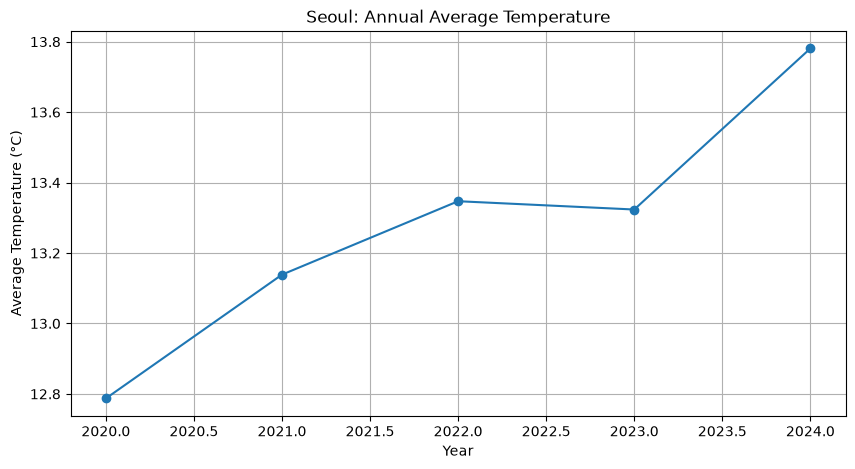

In [10]:
# 연도별 평균기온 시각화
# - 연도를 가로축, 평균기온을 세로축으로 설정
# - 선 그래프로 연도별 변화 확인
plt.figure(figsize=(10, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker='o')
plt.title('Seoul: Annual Average Temperature')
plt.xlabel('Year')
plt.ylabel('Average Temperature (°C)')
plt.grid(True)
plt.show()


Monthly temperature summary:
         AvgTemp    MaxTemp    MinTemp
Month                                 
1      -0.836774   3.210968  -4.443226
2       2.245775   6.556338  -1.733099
3       6.899355  11.820645   2.571613
4      11.552000  16.906667   6.862000
5      19.007742  24.399355  14.492903
6      22.590667  27.375333  18.636000
7      24.887097  28.750323  21.812903
8      26.051613  29.940645  22.732903
9      22.128667  26.866000  18.337333
10     14.988387  20.021935  10.580645
11      7.640000  12.075333   3.556000
12      1.574839   5.627097  -2.074194


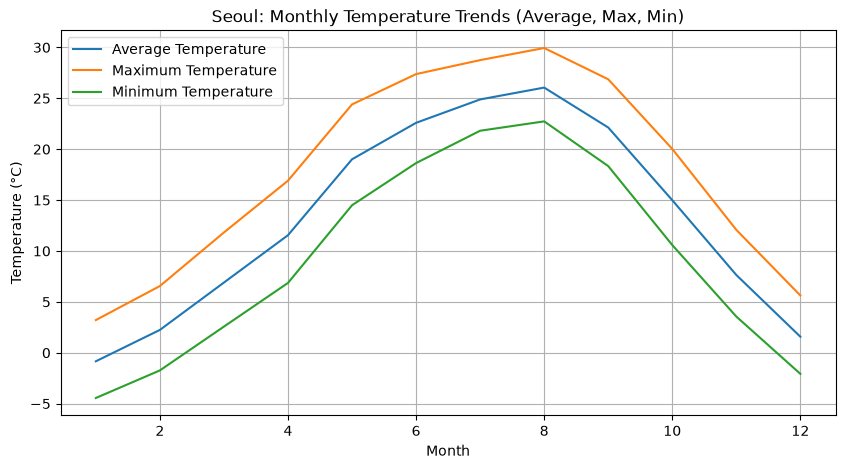

In [11]:
# 7. 월별 기온 변화 분석
# - 월별 평균기온, 최고기온, 최저기온 집계
# - 세 지표를 선 그래프로 비교
monthly_avg = df.groupby('Month')[['AvgTemp', 'MaxTemp', 'MinTemp']].mean() #월 그룹화 후 3개 온도에 대한 평균 집계
print("\nMonthly temperature summary:")
print(monthly_avg)

#시각화
plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg['AvgTemp'], label='Average Temperature')
plt.plot(monthly_avg.index, monthly_avg['MaxTemp'], label='Maximum Temperature')
plt.plot(monthly_avg.index, monthly_avg['MinTemp'], label='Minimum Temperature')
plt.title('Seoul: Monthly Temperature Trends (Average, Max, Min)')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

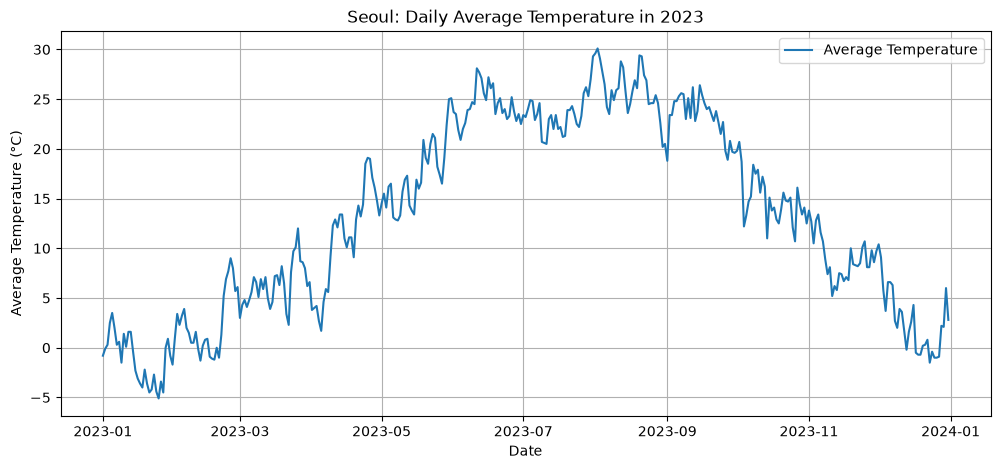

In [12]:
# 8. 특정 연도의 일별 기온 분석
# - 분석 연도를 2023년으로 지정
# - 해당 연도의 일별 평균기온 변화 시각화
year = 2023
df_2023 = df[df['Year'] == year]

plt.figure(figsize=(12, 5))
plt.plot(df_2023['Date'], df_2023['AvgTemp'], label='Average Temperature')
plt.title(f'Seoul: Daily Average Temperature in {year}')
plt.xlabel('Date')
plt.ylabel('Average Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

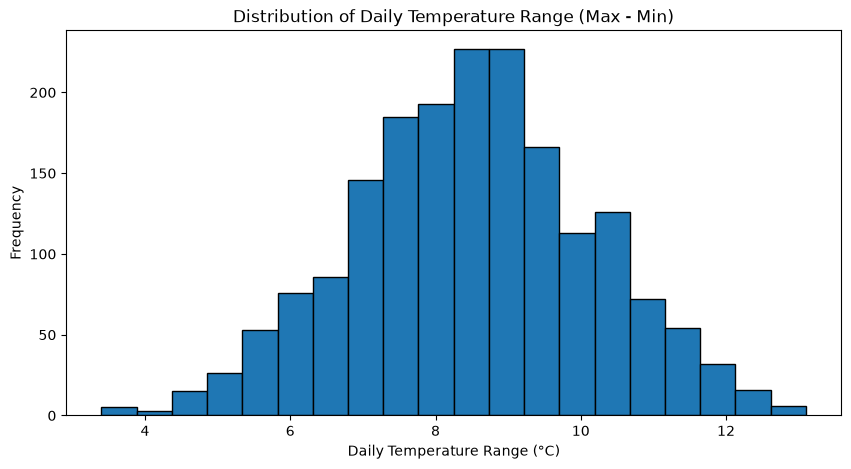

In [13]:
# 9. 일별 기온차 분석
# - 최고기온과 최저기온의 차이 계산
# - 히스토그램으로 일별 기온차 분포 확인
df['TempGap'] = df['MaxTemp'] - df['MinTemp']

plt.figure(figsize=(10, 5))
plt.hist(df['TempGap'], bins=20, edgecolor='black')
plt.title('Distribution of Daily Temperature Range (Max - Min)')
plt.xlabel('Daily Temperature Range (°C)')
plt.ylabel('Frequency')
plt.show()

In [14]:
# 10. 분석 결과 요약
# - 데이터 기간과 주요 기온 통계 출력
print("\n[Analysis Summary]")
print(f"- Data period: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"- Mean temperature: {df['AvgTemp'].mean():.2f}°C")
print(f"- Mean maximum temperature: {df['MaxTemp'].mean():.2f}°C")
print(f"- Mean minimum temperature: {df['MinTemp'].mean():.2f}°C")
print(f"- Mean daily temperature range: {df['TempGap'].mean():.2f}°C")
print("\nPractice completed: exploration, cleaning, visualization, and summary.")


[Analysis Summary]
- Data period: 2020-01-01 to 2024-12-31
- Mean temperature: 13.28°C
- Mean maximum temperature: 17.84°C
- Mean minimum temperature: 9.33°C
- Mean daily temperature range: 8.52°C

Practice completed: exploration, cleaning, visualization, and summary.
